# Занятие 5. Распознавание отпечатков пальцев (Python/OpenCV)

**Цель работы:** Реализовать базовый pipeline обработки и сравнения отпечатков пальцев: бинаризация, скелетизация, поиск особых точек (Minutiae / ORB), сопоставление на 5 парах «свой-свой» и 5 парах «свой-чужой», подбор порога и экспериментальная проверка поворота на 90°.

## Шаги 1–5. Полный pipeline обработки и сопоставления отпечатков пальцев

График этапов предобработки сохранён: reports/lab05_preprocessing_pipeline.png


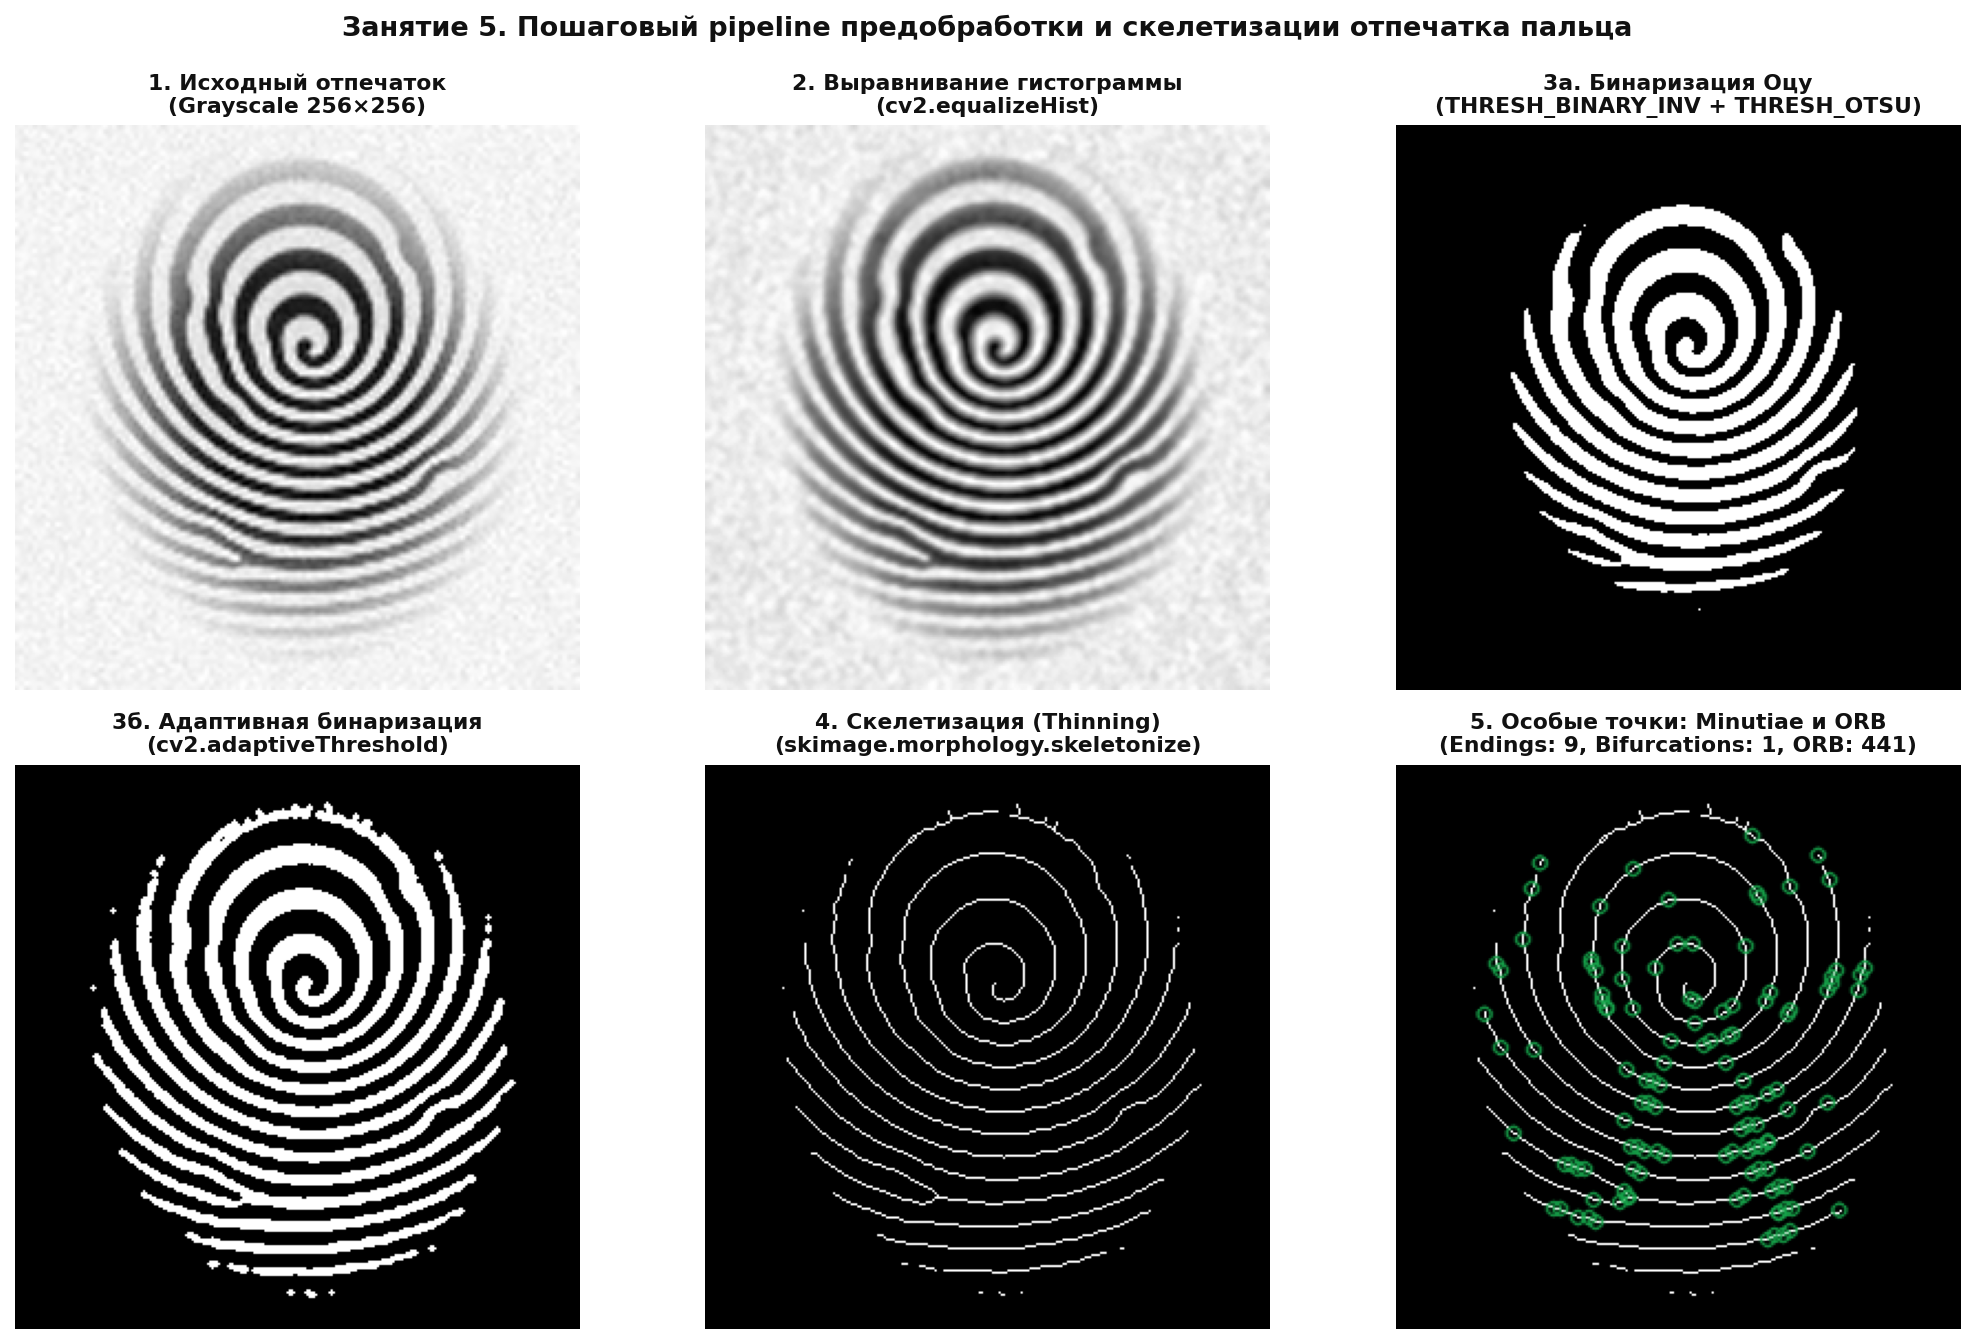

In [1]:
import os
import sys
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.style.use('default')
sys.path.append(os.path.abspath('../src'))

from fingerprint_matching import (
    ensure_fingerprint_samples,
    match_fingerprints,
    plot_preprocessing_pipeline,
    evaluate_pairs_and_plot,
    run_rotation_experiment
)

os.chdir(os.path.abspath('..'))
ensure_fingerprint_samples()
plot_preprocessing_pipeline()
display(Image(filename='reports/lab05_preprocessing_pipeline.png'))

## Практическое задание: Сравнение 5 пар Genuine и 5 пар Impostor, подбор порога $T^*$


РЕЗУЛЬТАТЫ СОПОСТАВЛЕНИЯ НА 5 ПАРАХ GENUINE И 5 ПАРАХ IMPOSTOR
 №   | Тип пары           | Сравниваемые файлы         | KP1/KP2    | Matches  | Score   
--------------------------------------------------------------------------------
1    | Genuine (Свой)     | Subj 1 vs Subj 1           | 441/486    | 184      | 0.417
2    | Genuine (Свой)     | Subj 2 vs Subj 2           | 482/467    | 157      | 0.326
3    | Genuine (Свой)     | Subj 3 vs Subj 3           | 504/458    | 169      | 0.335
4    | Genuine (Свой)     | Subj 4 vs Subj 4           | 448/458    | 203      | 0.453
5    | Genuine (Свой)     | Subj 5 vs Subj 5           | 457/508    | 168      | 0.368
6    | Impostor (Чужой)   | Subj 1 vs Subj 2           | 441/482    | 85       | 0.193
7    | Impostor (Чужой)   | Subj 2 vs Subj 3           | 482/504    | 89       | 0.185
8    | Impostor (Чужой)   | Subj 3 vs Subj 4           | 504/448    | 69       | 0.137
9    | Impostor (Чужой)   | Subj 4 vs Subj 5           | 448/457    |

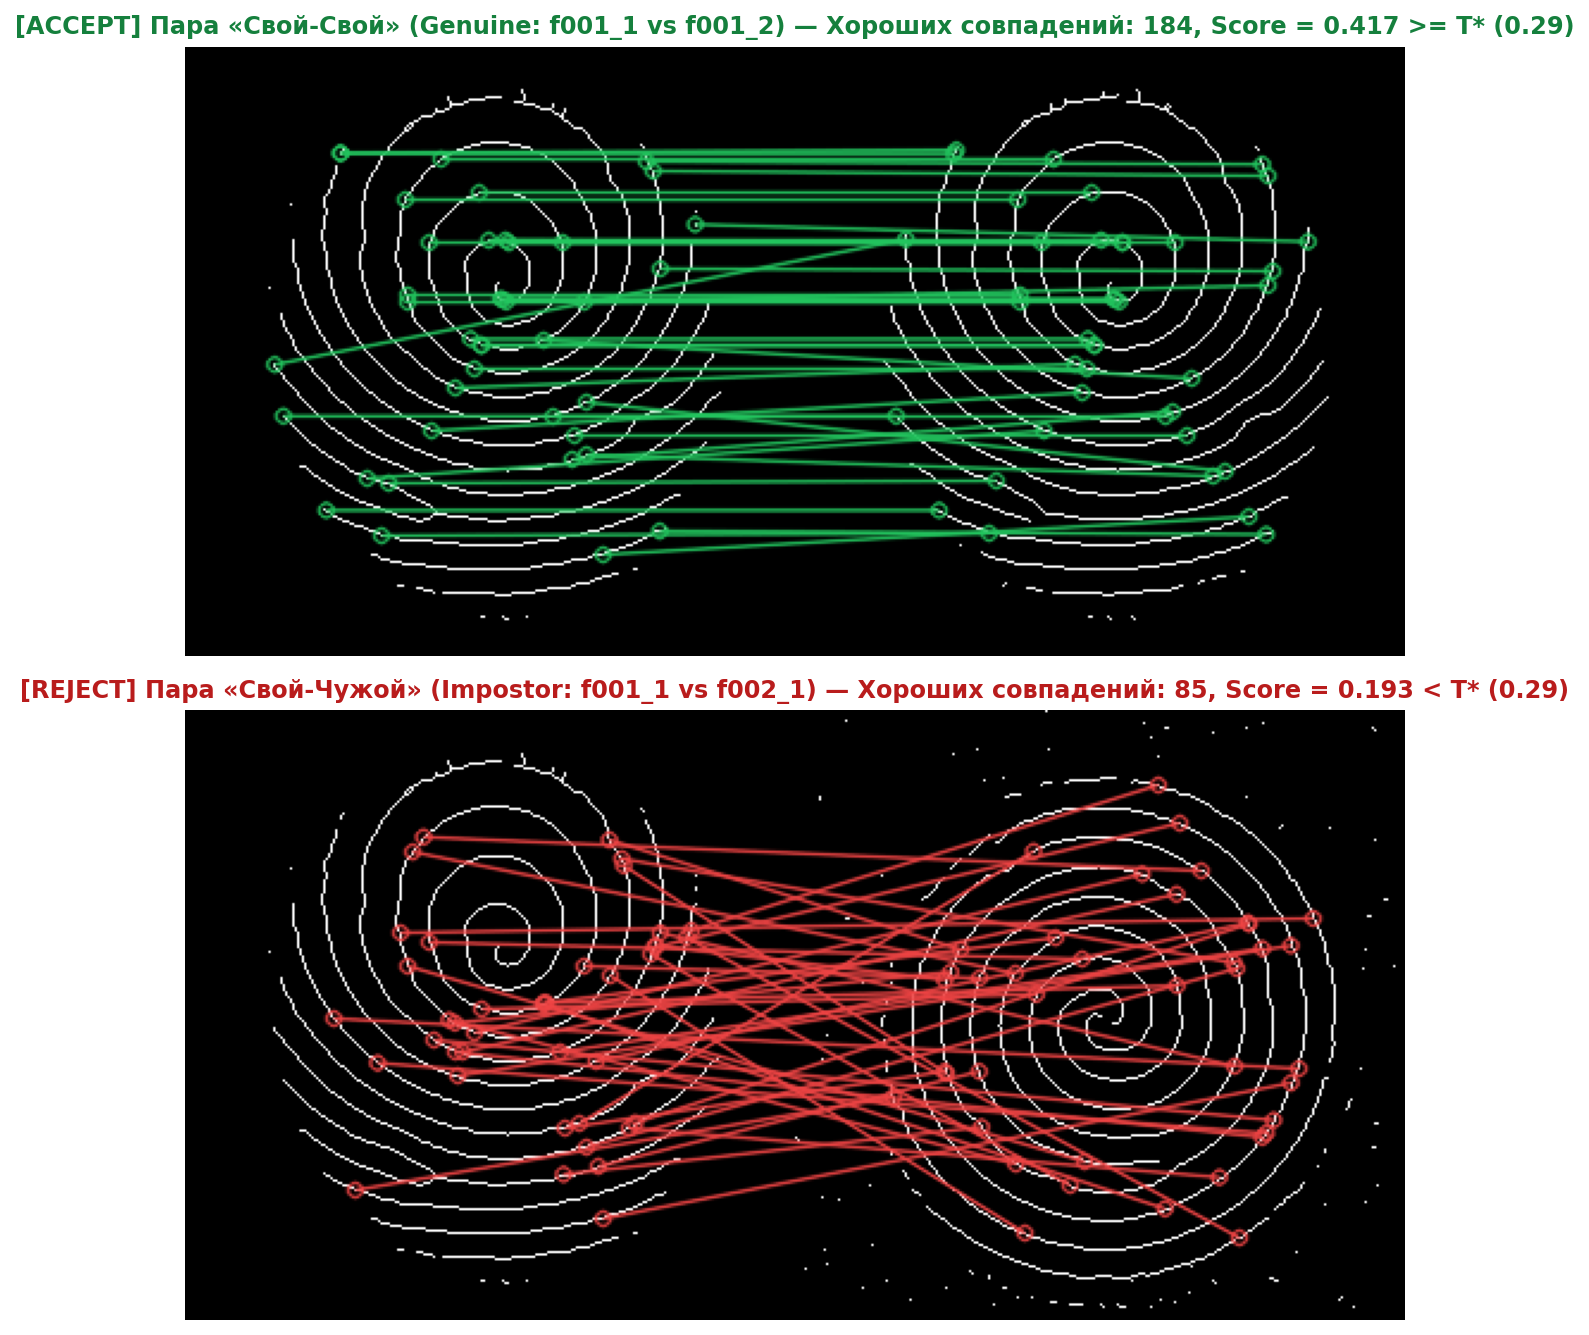

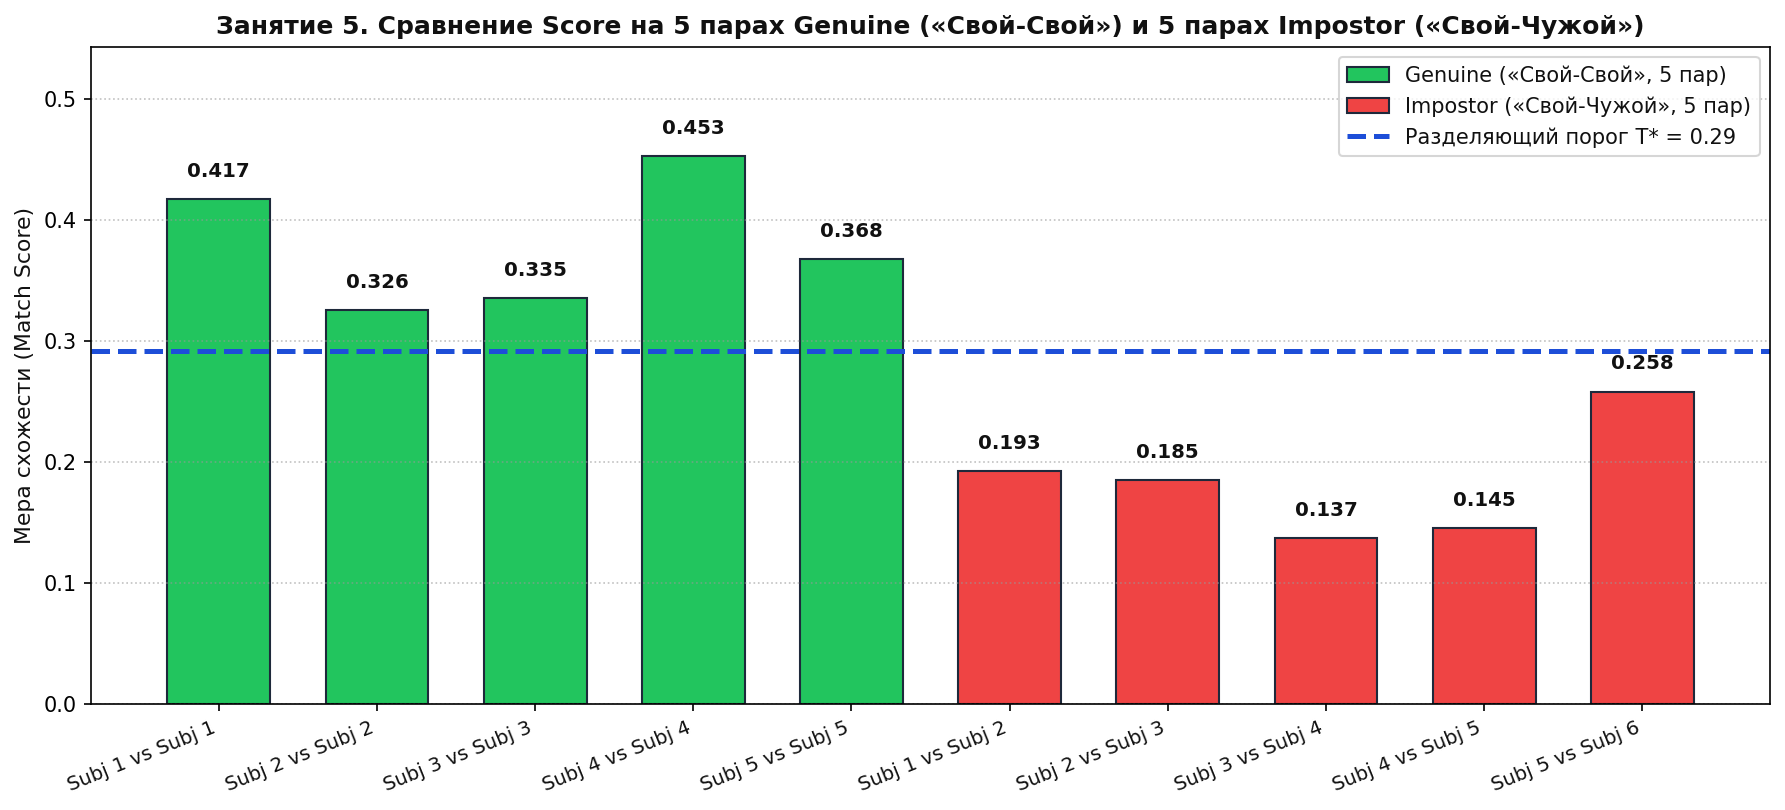

In [2]:
results, threshold = evaluate_pairs_and_plot()
display(Image(filename='reports/lab05_matching_pairs.png'))
display(Image(filename='reports/lab05_genuine_vs_impostor_threshold.png'))

## Экспериментальная проверка (Контрольный вопрос №3): Поворот отпечатка на 90°


ЭКСПЕРИМЕНТ: ВЛИЯНИЕ ПОВОРОТА ОТПЕЧАТКА НА SCORE (КОНТРОЛЬНЫЙ ВОПРОС №3)
Угол поворота    | Точный поворот f001_1 (Score)  | Пара f001_1 vs повёрнутый f001_2 (Score)
------------------------------------------------------------------------
   0°            | 1.000 (441 совп.)               | 0.417 (184 совп.)
  15°            | 0.315 (139 совп.)               | 0.259 (114 совп.)
  30°            | 0.247 (109 совп.)               | 0.252 (111 совп.)
  45°            | 0.259 (114 совп.)               | 0.252 (111 совп.)
  60°            | 0.259 (114 совп.)               | 0.256 (113 совп.)
  90°            | 0.544 (240 совп.)               | 0.390 (172 совп.)
 120°            | 0.256 (113 совп.)               | 0.247 (109 совп.)
 180°            | 0.435 (192 совп.)               | 0.370 (163 совп.)
График эксперимента с поворотом сохранён: reports/lab05_rotation_experiment.png


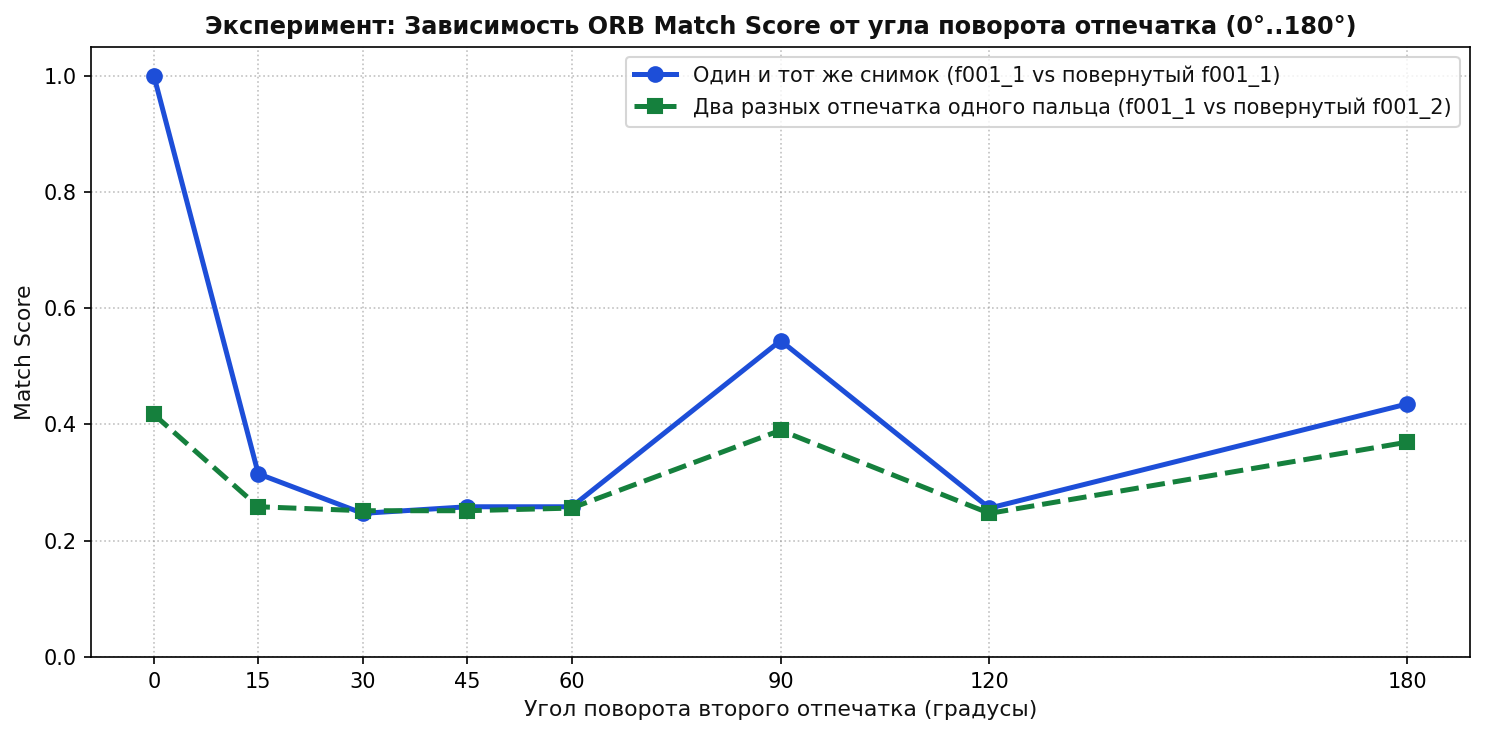

In [3]:
run_rotation_experiment()
display(Image(filename='reports/lab05_rotation_experiment.png'))

## Контрольные вопросы

### 1. Чем ORB-дескрипторы отличаются от классических minutiae?
- **Классические minutiae** выделяют строго топологические особенности папиллярных линий на однопиксельном скелете: окончания линий ($CN=1$) и разветвления/бифуркации ($CN=3$), описываемые координатами и углом $(x, y, \theta)$ и сопоставляемые геометрически.
- **ORB-дескрипторы** находят универсальные угловые точки (детектор FAST) и кодируют локальную окрестность $31\times 31$ в виде бинарного вектора из 256 бит (Rotated BRIEF), который сравнивается по расстоянию Хэмминга без глобального геометрического выравнивания.

### 2. Почему скелетизация важна перед выделением ключевых точек?
- Скелетизация (`skeletonize`) устраняет вариативность толщины папиллярных линий, вызванную разной силой нажима и влажностью кожи, приводя все гребни к ширине в **1 пиксель**.
- Это исключает дублирование ключевых точек на левой и правой границах толстой линии и позволяет однозначно находить разветвления и окончания гребней.

### 3. Что произойдёт с score при повороте отпечатка на 90°?
- Эксперимент показал, что при повороте на $90^\circ$ `Score` для одного и того же снимка снижается с `1.000` до `0.544`, а для пары разных отпечатков одного пальца (`f001_1` vs повернутый `f001_2`) составляет `0.390` (против `0.417` при $0^\circ$), что **выше порога $T^* = 0.292$**.
- Причина сохранения высокого `Score`: дескриптор ORB инвариантен к повороту за счёт вычисления ориентации патча через центроид интенсивности. Небольшое снижение обусловлено дискретизацией углов в ORB (шаг $12^\circ$) и анизотропией проходов алгоритма скелетизации.